# Overlay with an explicit layer contract

**Spatial methods · 15–25 minutes · original variant**

A 90-element map-first collection with bundled CSV/GeoJSON and clearly described synthetic boundaries.

**Learning question:** Which invented facilities overlap an assumed hazard cell?

**Source project:** [JupyterLite-Geospatial-Analyses-and-Maps](https://github.com/jltobias/JupyterLite-Geospatial-Analyses-and-Maps).

This original index activity is **synthetic teaching analysis**. It uses invented values or authored metadata, no real people or sensitive locations, no remote APIs, and no AI model calls. It is a small companion to the source project, not a reproduction of that project's full course.

![Learning workflow](../../assets/capabilities.svg)

Original atlas diagram, James L. Tobias and contributors, CC BY 4.0; see [asset provenance](../../visual-provenance.ipynb).


## Predict before running

Join facilities to a four-cell hazard lookup by a declared cell ID. An unmatched cell should be reported rather than assigned a zero.

Write a prediction and one assumption you would need to check. Run cells in order with **Shift+Enter**, or **Run → Run All Cells**. The next cell defines only local SVG display helpers; the following cell performs the analysis. Every graphic also prints its values as a text alternative.


In [1]:
from IPython.display import SVG, display
from html import escape

def svg(body, title, description, width=760, height=330):
    label = escape(title, quote=True)
    display(SVG(f'<svg xmlns="http://www.w3.org/2000/svg" viewBox="0 0 {width} {height}" role="img" aria-label="{label}"><title>{escape(title)}</title><desc>{escape(description)}</desc><rect width="100%" height="100%" fill="#f5f5ef" rx="12"/>{body}</svg>'))

def bars(values, title, unit):
    print(title + ' | ' + unit + ':', {k:round(v,3) for k,v in values.items()})
    n = len(values)
    height = max(250, 82 + n*36)
    maximum = max(max(values.values()), 1)
    body = f'<text x="22" y="30" font-family="sans-serif" font-size="18" fill="#123c45">{escape(title)}</text>'
    for i,(key,value) in enumerate(values.items()):
        y=58+i*36
        body += f'<text x="22" y="{y+17}" font-family="sans-serif" font-size="13">{escape(str(key))}</text><rect x="205" y="{y}" width="{max(0,value)/maximum*440:.2f}" height="23" rx="3" fill="#16756b"/><text x="{213+max(0,value)/maximum*440:.2f}" y="{y+17}" font-family="sans-serif" font-size="13">{value:.2f}</text>'
    body += f'<text x="205" y="{height-15}" font-family="sans-serif" font-size="12">zero baseline · {escape(unit)}</text>'
    svg(body, title, 'Values are printed as a text alternative; consult the chart title for data status.', height=height)

def grid(values, columns, title):
    print(title + ':', [round(v,3) for v in values])
    maximum = max(max(values),1)
    size = 54
    body = f'<text x="22" y="30" font-family="sans-serif" font-size="18">{escape(title)}</text>'
    for i,v in enumerate(values):
        x=25+(i%columns)*size; y=52+(i//columns)*size
        light=92-50*v/maximum
        body += f'<rect x="{x}" y="{y}" width="50" height="50" fill="hsl(169,45%,{light:.1f}%)" stroke="#123c45"/><text x="{x+25}" y="{y+29}" text-anchor="middle" font-family="sans-serif" font-size="14" fill="#061c21">{v:.1f}</text>'
    svg(body,title,'Synthetic grid with values printed in each cell; no actual boundaries.',height=max(220,70+((len(values)+columns-1)//columns)*size))

def lines(series, title, xunit, yunit):
    print(title + ':', {k:[round(v,3) for v in vs] for k,vs in series.items()})
    maximum=max(max(vs) for vs in series.values()) or 1
    body=f'<text x="22" y="30" font-family="sans-serif" font-size="18">{escape(title)}</text><path d="M55 55V265H710" fill="none" stroke="#123c45"/>'
    for j,(name,vs) in enumerate(series.items()):
        color=['#16756b','#a34712','#41449c'][j%3]
        pts=' '.join(f'{55+i*650/max(1,len(vs)-1):.1f},{265-v*200/maximum:.1f}' for i,v in enumerate(vs))
        body+=f'<polyline points="{pts}" fill="none" stroke="{color}" stroke-width="3"/><text x="{60+j*220}" y="310" font-family="sans-serif" font-size="13" fill="{color}">{escape(name)}</text>'
    body+=f'<text x="55" y="288" font-family="sans-serif" font-size="12">{escape(xunit)} → · {escape(yunit)} ↑ · y starts at zero</text>'
    svg(body,title,'Synthetic series; printed values are the text alternative.')


Unmatched facilities: ['F4']
Synthetic overlay lookup | hazard index: {'F1': 2, 'F2': 9, 'F3': 7}


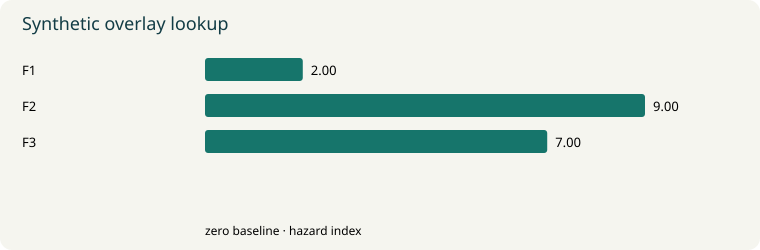

In [2]:
hazard = {'A': 2, 'B': 7, 'C': 4, 'D': 9}
facilities = [('F1','A'), ('F2','D'), ('F3','B'), ('F4','X')]
joined = {name: hazard[cell] for name,cell in facilities if cell in hazard}
missing = [name for name,cell in facilities if cell not in hazard]
print('Unmatched facilities:', missing)
assert missing == ['F4']
bars(joined, 'Synthetic overlay lookup', 'hazard index')


## Interpret the result

The missing facility is unknown, not safe. A layer contract must state geography, units, identifiers and missing-value policy before overlay.

Name the result, the assumption producing it, and one conclusion it cannot support. These are not clinical findings, causal effects or live model outputs.

## Change one thing

Add a second time slice and distinguish missing cells from changing hazard. Which fields belong in the export?

Save a copy with **File → Save and Export Notebook As → Notebook** (or the file browser's Download command). Browser storage is local to this browser/profile; it is not a GitHub commit or shared database.


## Connect the idea

Compare this activity with another chapter on the same [learning path](../../index.ipynb). Keep the question, data status and interpretation visible when transferring a method.


## Sources, continuation and limits

**Source repository:** [JupyterLite-Geospatial-Analyses-and-Maps](https://github.com/jltobias/JupyterLite-Geospatial-Analyses-and-Maps).

**Source README:** [reviewed immutable version](https://github.com/jltobias/JupyterLite-Geospatial-Analyses-and-Maps/blob/7ff9306b61deeb68047e7c31cd4c2ccc3cc76d72/README.md); inspected 2026-11-01, commit `7ff9306b61de`. Repository content and linked works keep their original terms. Summaries and exercises here are newly authored.

The source describes synthetic shapefiles, administrative outlines and health facilities. None is imported here or labeled as an actual administrative boundary. README gives deployment guidance but no exact launch URL.

No exact published launch URL is documented in this README. Use the repository source; hosted availability is unverified.

**Runtime budget:** this default is fewer than 100 values and normally completes within seconds; allow 60 seconds per cell while first loading Python. For native/GPU tools, use the source's local/server guide in an isolated environment, start with one small public/synthetic fixture, limit a trial to 5 minutes, and inspect memory, provider costs and outputs before scaling. For live models, use an approved authenticated backend with server-side secrets and a bounded single request; do not put credentials or sensitive records into a browser. Nothing in this chapter calls those services.

[Central references](../../references.ipynb) · [Contribute](../../contributor-guide.ipynb)
